PROGRAM STARTED - Initializing FNN and CNN...

[FNN 1/7] Loading Fashion-MNIST dataset...
29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Fashion-MNIST dataset loaded successfully!

[FNN 2/7] Flattening and normalizing images...
FNN data preprocessing completed!

[FNN 3/7] Building the model...
FNN model created!

[FNN 4/7] Compiling the model...
FNN model compiled!

[FNN 5/7] TRAINING STARTED - Please wait...
Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 15s 6ms/step - accuracy: 0.8030 - loss: 0.5526 - val_accuracy: 0.8505 - val_loss: 0.4056
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 20s 6ms/step - accuracy: 0.8488 - loss: 0.4148 - val_accuracy: 0.8590 - val_loss: 0.3803
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.8612 - loss: 0.3795 - val_accuracy: 0.8615 - val_loss: 0.3797
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - ac

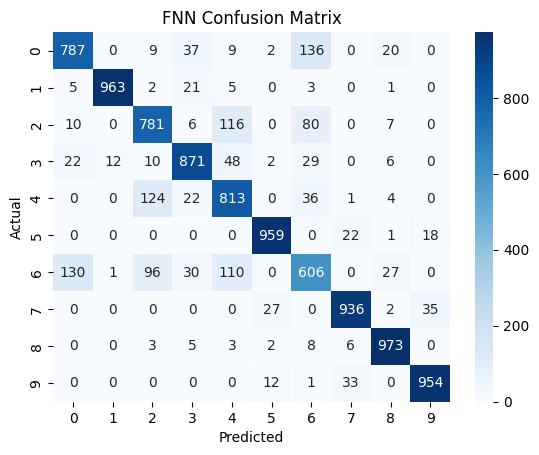

Plotting FNN accuracy and loss...


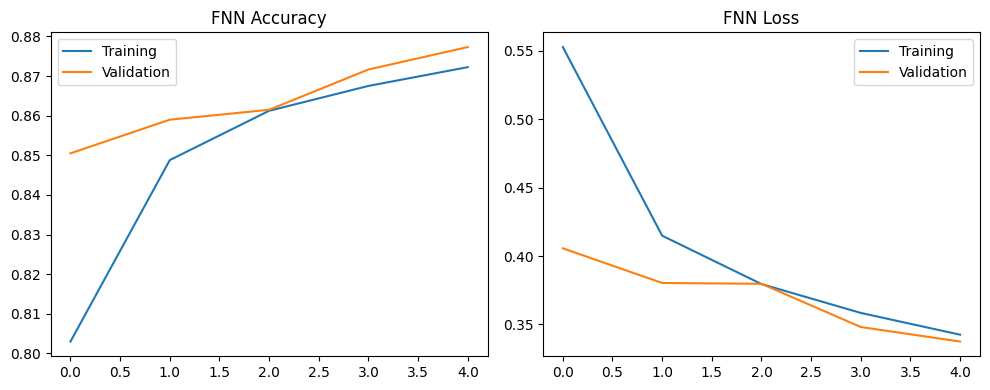

FNN PART COMPLETED!

[CNN 1/7] Loading MNIST digit dataset...
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
MNIST dataset loaded successfully!

[CNN 2/7] Normalizing images and adding channel dimension...
CNN data preprocessing completed!

[CNN 3/7] Building the model...
CNN model created!

[CNN 4/7] Compiling the model...
CNN model compiled!

[CNN 5/7] TRAINING STARTED - Please wait...
Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 60s 34ms/step - accuracy: 0.9368 - loss: 0.2075 - val_accuracy: 0.9853 - val_loss: 0.0508
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 54s 32ms/step - accuracy: 0.9774 - loss: 0.0755 - val_accuracy: 0.9893 - val_loss: 0.0373
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 83s 33ms/step - accuracy: 0.9838 - loss: 0.0545 - val_accuracy: 0.9917 - val_loss: 0.0340
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 55s 32ms/step - accuracy: 0.9865 - loss: 0.0451 - val_accuracy: 0.9898 - val_loss: 0.0349
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 54s 32ms/step - accuracy: 0.9883 - loss:

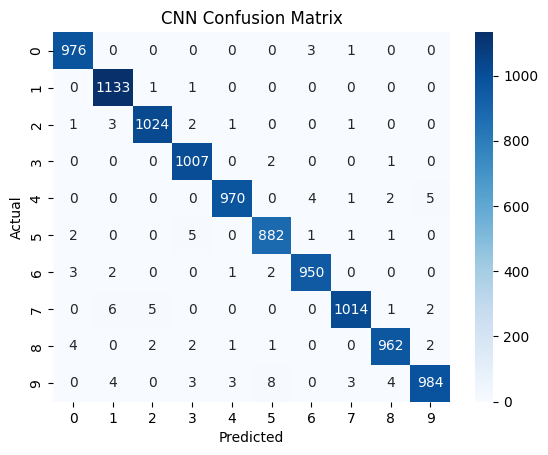

Plotting CNN accuracy and loss...


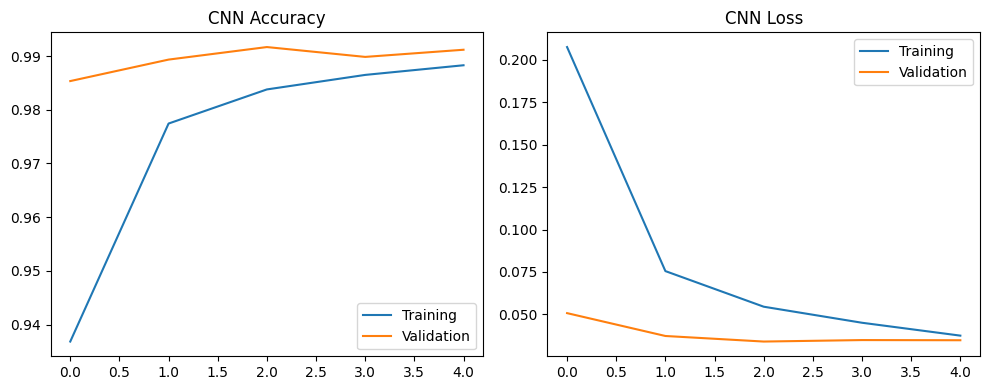

Displaying sample CNN predictions...


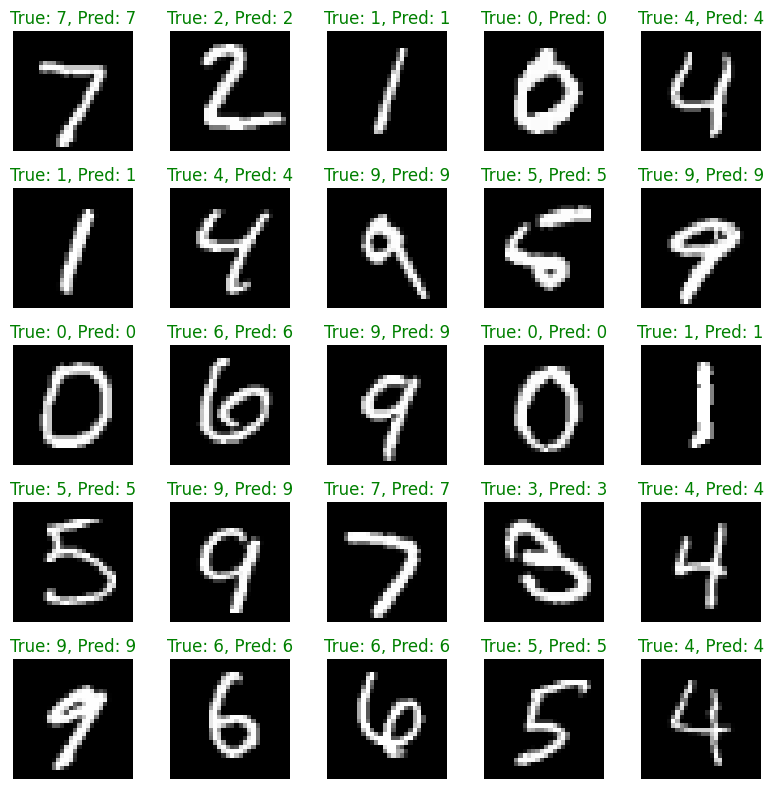


ALL PROCESSING COMPLETED SUCCESSFULLY!


In [1]:

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import fashion_mnist, mnist
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

print("PROGRAM STARTED - Initializing FNN and CNN...")

# ==========================
# PART 1: FNN
# ==========================

print("\n[FNN 1/7] Loading Fashion-MNIST dataset...")
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()
print("Fashion-MNIST dataset loaded successfully!")

print("\n[FNN 2/7] Flattening and normalizing images...")
x_train_fnn = x_train.reshape(-1, 784).astype("float32") / 255.0
x_test_fnn = x_test.reshape(-1, 784).astype("float32") / 255.0
print("FNN data preprocessing completed!")

print("\n[FNN 3/7] Building the model...")
fnn = models.Sequential([
    layers.Input(shape=(784,)),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax")
])
print("FNN model created!")

print("\n[FNN 4/7] Compiling the model...")
fnn.compile(optimizer="adam",
            loss="sparse_categorical_crossentropy",
            metrics=["accuracy"])
print("FNN model compiled!")

print("\n[FNN 5/7] TRAINING STARTED - Please wait...")
history_fnn = fnn.fit(
    x_train_fnn, y_train,
    epochs=5, validation_split=0.1, verbose=1
)
print("FNN training completed!")

print("\n[FNN 6/7] Evaluating the model...")
loss, acc = fnn.evaluate(x_test_fnn, y_test, verbose=0)
print("FNN Test Accuracy:", round(acc, 4))

print("Generating FNN predictions...")
pred_fnn = np.argmax(fnn.predict(x_test_fnn, verbose=0), axis=1)

print("\nFNN Classification Report:")
print(classification_report(y_test, pred_fnn))

print("Displaying FNN confusion matrix...")
sns.heatmap(confusion_matrix(y_test, pred_fnn),
            annot=True, fmt="d", cmap="Blues")
plt.title("FNN Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

print("Plotting FNN accuracy and loss...")
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history_fnn.history["accuracy"], label="Training")
plt.plot(history_fnn.history["val_accuracy"], label="Validation")
plt.title("FNN Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_fnn.history["loss"], label="Training")
plt.plot(history_fnn.history["val_loss"], label="Validation")
plt.title("FNN Loss")
plt.legend()

plt.tight_layout()
plt.show()

print("FNN PART COMPLETED!")

# ==========================
# PART 2: CNN
# ==========================

print("\n[CNN 1/7] Loading MNIST digit dataset...")
(x_train, y_train), (x_test, y_test) = mnist.load_data()
print("MNIST dataset loaded successfully!")

print("\n[CNN 2/7] Normalizing images and adding channel dimension...")
x_train_cnn = x_train[..., np.newaxis].astype("float32") / 255.0
x_test_cnn = x_test[..., np.newaxis].astype("float32") / 255.0
print("CNN data preprocessing completed!")

print("\n[CNN 3/7] Building the model...")
cnn = models.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(10, activation="softmax")
])
print("CNN model created!")

print("\n[CNN 4/7] Compiling the model...")
cnn.compile(optimizer="adam",
            loss="sparse_categorical_crossentropy",
            metrics=["accuracy"])
print("CNN model compiled!")

print("\n[CNN 5/7] TRAINING STARTED - Please wait...")
history_cnn = cnn.fit(
    x_train_cnn, y_train,
    epochs=5, validation_split=0.1, verbose=1
)
print("CNN training completed!")

print("\n[CNN 6/7] Evaluating the model...")
loss, acc = cnn.evaluate(x_test_cnn, y_test, verbose=0)
print("CNN Test Accuracy:", round(acc, 4))

print("Generating CNN predictions...")
pred_cnn = np.argmax(cnn.predict(x_test_cnn, verbose=0), axis=1)

print("\nCNN Classification Report:")
print(classification_report(y_test, pred_cnn))

print("Displaying CNN confusion matrix...")
sns.heatmap(confusion_matrix(y_test, pred_cnn),
            annot=True, fmt="d", cmap="Blues")
plt.title("CNN Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

print("Plotting CNN accuracy and loss...")
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history_cnn.history["accuracy"], label="Training")
plt.plot(history_cnn.history["val_accuracy"], label="Validation")
plt.title("CNN Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_cnn.history["loss"], label="Training")
plt.plot(history_cnn.history["val_loss"], label="Validation")
plt.title("CNN Loss")
plt.legend()

plt.tight_layout()
plt.show()

print("Displaying sample CNN predictions...")
plt.figure(figsize=(8, 8))

for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.imshow(x_test[i], cmap="gray")
    plt.title(
        f"True: {y_test[i]}, Pred: {pred_cnn[i]}",
        color="green" if y_test[i] == pred_cnn[i] else "red"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

print("\nALL PROCESSING COMPLETED SUCCESSFULLY!")
